# Xây dựng mô hình SVM trên dữ liệu bệnh tiểu đường

## 0. Import thư viện


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

## 1. Chuẩn bị dữ liệu

In [30]:
df = pd.read_csv("diabetes.csv")
print(df.shape)

(768, 9)


### 1.1. Chuyển giá trị 0 không hợp lệ thành NaN

In [31]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

# Đổi 0 vô lý -> NaN (chạy 1 lần, nếu chạy lại cũng không sao)
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols] = df[cols].replace(0, np.nan)

X = df.drop(columns="Outcome")
y = df["Outcome"]



### 1.2. Chia dữ liệu theo 80/20 với random-state là 42

In [32]:
# Chia train/test TRƯỚC khi điền thiếu
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Kích thước:", X_train.shape, X_test.shape)
print("Tỉ lệ lớp (train):")
print(y_train.value_counts(normalize=True))
print("\nGiá trị thiếu (train):")
print(X_train.isnull().sum())

Kích thước: (614, 8) (154, 8)
Tỉ lệ lớp (train):
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

Giá trị thiếu (train):
Pregnancies                   0
Glucose                       4
BloodPressure                23
SkinThickness               175
Insulin                     290
BMI                           9
DiabetesPedigreeFunction      0
Age                           0
dtype: int64


### 1.3. Cấu hình điền giá trị thiếu bằng median

Sử dụng `SimpleImputer(strategy="median")` để điền giá trị thiếu bằng trung vị của từng cột.

Ở bước này chỉ khởi tạo bộ điền thiếu. Khi gọi `model.fit(X_train, y_train)` trong mục 2, Pipeline sẽ học median từ tập train, điền giá trị thiếu, chuẩn hóa rồi huấn luyện SVM. Khi dự đoán trên test, Pipeline sử dụng lại median đã học từ train.


In [33]:
imputer = SimpleImputer(strategy="median")


## 2. Tiền xử lý và huấn luyện SVM

Sử dụng Pipeline gồm ba bước:
- Điền giá trị thiếu bằng median của tập huấn luyện.
- Chuẩn hóa các đặc trưng bằng StandardScaler.
- Huấn luyện SVM với kernel RBF.

In [34]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

model = Pipeline([
    ("imputer", imputer),
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Pregnancies','Glucose','BloodPressure',...,'BMI', 'DiabetesPedigreeFunction','Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For str

## 3. Dự đoán và đánh giá mô hình

Accuracy trên train: 0.8403908794788274
Accuracy trên test: 0.7402597402597403

Báo cáo phân loại:
                precision    recall  f1-score   support

Không mắc bệnh     0.7778    0.8400    0.8077       100
      Mắc bệnh     0.6522    0.5556    0.6000        54

      accuracy                         0.7403       154
     macro avg     0.7150    0.6978    0.7038       154
  weighted avg     0.7337    0.7403    0.7349       154



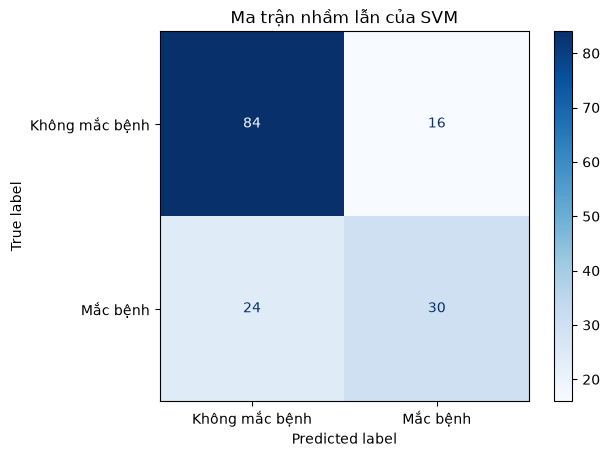

In [35]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

y_pred = model.predict(X_test)

print("Accuracy trên train:", model.score(X_train, y_train))
print("Accuracy trên test:", accuracy_score(y_test, y_pred))

print("\nBáo cáo phân loại:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Không mắc bệnh", "Mắc bệnh"],
    digits=4,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Không mắc bệnh", "Mắc bệnh"],
    cmap="Blues"
)
plt.title("Ma trận nhầm lẫn của SVM")
plt.show()

## 4. Nhận xét

- **Độ chính xác:** Accuracy trên tập train đạt **84,04%**, trên tập test đạt **74,03%**, tương ứng dự đoán đúng **114/154 mẫu test**.
- **Kết quả đối với lớp mắc bệnh:** Precision đạt **65,22%**, recall đạt **55,56%** và F1-score đạt **60,00%**. Mô hình nhận diện đúng **30/54 mẫu mắc bệnh**; khả năng nhận diện lớp này còn hạn chế.
- **Các trường hợp dự đoán sai:** Có **24 mẫu mắc bệnh bị dự đoán thành không mắc bệnh (FN)** và **16 mẫu không mắc bệnh bị dự đoán thành mắc bệnh (FP)**. Tỉ lệ bỏ sót trong lớp mắc bệnh là **44,44%**.
- **So sánh hai lớp:** Recall của lớp không mắc bệnh đạt **84,00%**, cao hơn lớp mắc bệnh (**55,56%**). Vì vậy, chỉ nhìn accuracy tổng thể chưa thể hiện đầy đủ hạn chế của mô hình đối với lớp mắc bệnh.
- **Chênh lệch train/test:** Accuracy trên train cao hơn test khoảng **10,01 điểm phần trăm**. Đây là dấu hiệu cần xem xét khả năng overfitting; chưa đủ để khẳng định chỉ dựa trên một lần chia train/test.

**Kết luận:** Mô hình SVM với kernel RBF đã hoàn thành luồng điền thiếu bằng median, chuẩn hóa, huấn luyện và đánh giá. Kết quả có thể dùng làm mô hình cơ sở cho bài thực hành, nhưng cần cải thiện khả năng nhận diện lớp mắc bệnh và đánh giá thêm độ ổn định của kết quả.
